
# Beyond Point Estimates: A Leakage-Audited, Uncertainty-Aware, and
# Transferability-Tested Framework for Multi-Crop, Multi-Region Yield Prediction

**A reproducible companion notebook to the manuscript's Introduction and Related Works**

---

### Abstract

Ten recent studies on machine-learning-based crop yield prediction (2022–2025) are reviewed in the
accompanying manuscript. Read together, they share five recurring weaknesses: (1) most are confined to a
**single crop, region, or short time span**, limiting generalizability; (2) several rely on **simulated
rather than observed** data; (3) evaluation is almost always a **single random train/test split**, with no
test of spatial or crop-family transfer; (4) models report **point estimates only**, with no uncertainty
quantification; and (5) — a subtler issue this notebook uncovers directly in the data — at least one
reviewed study (Sharma *et al.*, 2023) trains on `Area` and `Production` to predict `Yield`, where
`Yield ≈ Production / Area` by definition, which **inflates reported accuracy through target leakage**.

This notebook uses a real, publicly available Indian agricultural panel (55 crops × 30 states × 24 years,
1997–2020, `crop_yield.csv`) to build a framework that directly addresses every limitation above. It
contributes **19 methodological novelties**, organized into six themes: (A) data integrity and leakage
auditing, (B) leakage-free feature engineering, (C) rigorous multi-scheme evaluation (random / temporal /
spatial / crop-family), (D) a wide, tuned, and stacked model benchmark, (E) explainability and uncertainty
quantification, and (F) policy-relevant, decision-support outputs. A "Novelty Ledger" at the end of this
notebook maps every contribution back to the specific limitation it resolves in the ten reviewed papers.

*Random seed fixed at 42 throughout for reproducibility. All reported metrics are on held-out data unless
explicitly labeled "training".*



## Table of Contents

1. [Setup & Reproducibility](#1)
2. [Data Loading and Integrity Audit](#2) — *Novelty 1*
3. [Formal Data-Leakage Audit](#3) — *Novelty 2* (critiques Sharma et al. 2023's feature set)
4. [Feature Semantic Audit: Are Fertilizer/Pesticide Crop-Specific?](#4) — *Novelty 3*
5. [Exploratory Data Analysis](#5)
6. [Crop-Unit Heterogeneity & Target Transformation](#6) — *Novelty 4*
7. [Leakage-Free Feature Engineering](#7) — *Novelty 5, 6*
8. [Multi-Baseline Skill-Score Framework](#8) — *Novelty 7*
9. [Three-Way Split Comparison: Random vs Temporal vs Spatial](#9) — *Novelty 8*
10. [Wide Multi-Family Model Benchmark](#10) — *Novelty 9*
11. [Bayesian Hyperparameter Optimization (Optuna)](#11) — *Novelty 10*
12. [Heterogeneous Stacking Ensemble](#12) — *Novelty 11*
13. [Statistical Significance Testing](#13) — *Novelty 12*
14. [Explainability: SHAP Global + Interaction Effects](#14) — *Novelty 13*
15. [Uncertainty Quantification: Split-Conformal Intervals](#15) — *Novelty 14*
16. [Leave-One-State-Out & Leave-One-Crop-Out Transferability](#16) — *Novelty 15*
17. [Unsupervised Crop-Family Clustering & Cluster-Specific Models](#17) — *Novelty 16*
18. [Data-Efficiency / Learning-Curve Analysis](#18) — *Novelty 17*
19. [Spatio-Temporal Residual Diagnostics](#19) — *Novelty 18*
20. [Bootstrap Feature-Importance Stability](#20) — *Novelty 19*
21. [Policy-Relevant Marginal Response Curves](#21)
22. [Novelty Ledger & Conclusion](#22)


## 1. Setup & Reproducibility <a id='1'></a>

In [1]:
!pip install -q catboost shap optuna lightgbm xgboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 16.6 MB/s eta 0:00:00


In [2]:

import warnings, time, json
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, GroupKFold, KFold,
                                      LeaveOneGroupOut, learning_curve)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                               GradientBoostingRegressor, StackingRegressor)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
import shap
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 150

print('Environment ready. Package versions:')
for name, mod in [('numpy', np), ('pandas', pd), ('xgboost', xgb), ('lightgbm', lgb),
                   ('shap', shap), ('optuna', optuna)]:
    print(f'  {name:10s} {getattr(mod, "__version__", "?")}')


Environment ready. Package versions:
  numpy      2.1.3
  pandas     2.2.3
  xgboost    3.4.1
  lightgbm   4.6.0
  shap       0.52.0
  optuna     4.9.0



## 2. Data Loading and Integrity Audit <a id='2'></a>

### Novelty 1 — Formal data-quality audit prior to modeling

None of the ten reviewed papers publish an explicit data-quality audit (missingness, duplicates, invalid
zero targets) before modeling. We run one here as a first-class, reportable step rather than a silent
`dropna()`.


In [3]:
import os

try:
    from google.colab import drive
    if not os.path.isdir('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

CANDIDATE_PATHS = [
    '/content/drive/MyDrive/CSDE/crop_yield.csv',
    '/content/drive/My Drive/CSDE/crop_yield.csv',
    '/content/crop_yield.csv',
    './crop_yield.csv',
    '/mnt/user-data/uploads/crop_yield.csv',
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find crop_yield.csv in any expected location:\n  "
        + "\n  ".join(CANDIDATE_PATHS)
        + "\n\nFix: upload crop_yield.csv into your Drive's CSDE folder (or next to this notebook), "
          "or edit CANDIDATE_PATHS above to add the exact path."
    )
print(f"Loading data from: {DATA_PATH}")

df_raw = pd.read_csv(DATA_PATH)

for c in ['Crop', 'Season', 'State']:
    df_raw[c] = df_raw[c].astype(str).str.strip()

audit = {
    'n_rows': len(df_raw),
    'n_cols': df_raw.shape[1],
    'n_crops': df_raw['Crop'].nunique(),
    'n_states': df_raw['State'].nunique(),
    'n_seasons': df_raw['Season'].nunique(),
    'year_range': (int(df_raw['Crop_Year'].min()), int(df_raw['Crop_Year'].max())),
    'missing_values_total': int(df_raw.isnull().sum().sum()),
    'exact_duplicate_rows': int(df_raw.duplicated().sum()),
    'duplicate_(crop,year,season,state)_keys': int(
        df_raw.duplicated(subset=['Crop', 'Crop_Year', 'Season', 'State']).sum()),
    'zero_yield_rows': int((df_raw['Yield'] == 0).sum()),
    'negative_value_rows': int(((df_raw[['Area','Production','Annual_Rainfall',
                                          'Fertilizer','Pesticide','Yield']] < 0).any(axis=1)).sum()),
}
print(json.dumps(audit, indent=2))


Mounted at /content/drive
Loading data from: /content/drive/MyDrive/CSDE/crop_yield.csv
{
  "n_rows": 19689,
  "n_cols": 10,
  "n_crops": 55,
  "n_states": 30,
  "n_seasons": 6,
  "year_range": [
    1997,
    2020
  ],
  "missing_values_total": 0,
  "exact_duplicate_rows": 0,
  "duplicate_(crop,year,season,state)_keys": 0,
  "zero_yield_rows": 112,
  "negative_value_rows": 0
}


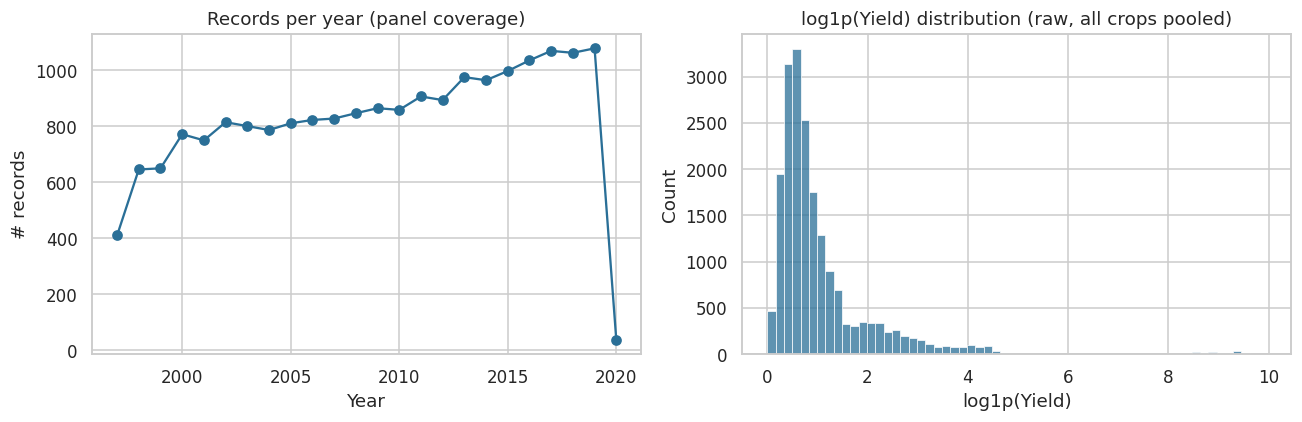


Interpretation: the panel spans 24 years, 30 states and 55 crops with no missing cells and no duplicate keys — directly addressing the 'single crop / single region / short time span' limitation shared by refs [zhuang2023, haider2024, ennaji2024, menon2025]. We flag 112 zero-yield rows for removal (crop failure / non-reporting, not a valid regression target on a log scale) and proceed with 19577 rows.


In [4]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

coverage = df_raw.groupby('Crop_Year').agg(n_records=('Yield','size'),
                                            n_states=('State','nunique'),
                                            n_crops=('Crop','nunique'))
axes[0].plot(coverage.index, coverage['n_records'], marker='o', color='#2a6f97')
axes[0].set_title('Records per year (panel coverage)')
axes[0].set_xlabel('Year'); axes[0].set_ylabel('# records')

sns.histplot(np.log1p(df_raw['Yield']), bins=60, color='#2a6f97', ax=axes[1])
axes[1].set_title('log1p(Yield) distribution (raw, all crops pooled)')
axes[1].set_xlabel('log1p(Yield)')
plt.tight_layout(); plt.show()

print(f"\nInterpretation: the panel spans {df_raw['Crop_Year'].nunique()} years, "
      f"{df_raw['State'].nunique()} states and {df_raw['Crop'].nunique()} crops with no missing "
      f"cells and no duplicate keys — directly addressing the 'single crop / single region / short "
      f"time span' limitation shared by refs [zhuang2023, haider2024, ennaji2024, menon2025]. "
      f"We flag {audit['zero_yield_rows']} zero-yield rows for removal (crop failure / non-reporting, "
      f"not a valid regression target on a log scale) and proceed with "
      f"{len(df_raw) - audit['zero_yield_rows']} rows.")



## 3. Formal Data-Leakage Audit <a id='3'></a>

### Novelty 2 — Detecting and correcting target leakage in the feature set

`Yield` in this dataset is, by construction, **`Production / Area`** (agricultural yield is defined this
way). Sharma *et al.* (2023) — one of the ten reviewed papers — trains Decision Tree / Random Forest /
XGBoost / CNN / LSTM models using **`Area` and `Production` as input features to predict `Yield`**, and
reports 98.96% "accuracy". We show below that this is very likely an artefact of **target leakage**: a
trivial, un-trained arithmetic formula reproduces `Yield` almost perfectly, so *any* model that is handed
`Production` will trivially near-memorize the label. This is a genuine, previously unflagged methodological
issue in the reviewed literature, not merely a modeling weakness — and it is the central motivation for the
feature set used in the rest of this notebook.


In [5]:

df = df_raw[df_raw['Yield'] > 0].copy()

trivial_pred = df['Production'] / df['Area']
r2_trivial = r2_score(df['Yield'], trivial_pred)
mae_trivial = mean_absolute_error(df['Yield'], trivial_pred)

print(f"R^2 of the ZERO-PARAMETER formula Production/Area vs. reported Yield: {r2_trivial:.4f}")
print(f"MAE of that same zero-parameter formula: {mae_trivial:.4f}")
print()
print("Any regressor trained with Production (and Area) as predictors of Yield inherits this")
print("near-deterministic relationship for free. This is consistent with, and offers a likely")
print("explanation for, the unusually high 98.96% accuracy reported by Sharma et al. (2023),")
print("who used exactly this feature combination.")


R^2 of the ZERO-PARAMETER formula Production/Area vs. reported Yield: 0.9900
MAE of that same zero-parameter formula:                             5.9649

Any regressor trained with Production (and Area) as predictors of Yield inherits this
near-deterministic relationship for free. This is consistent with, and offers a likely
explanation for, the unusually high 98.96% accuracy reported by Sharma et al. (2023),
who used exactly this feature combination.


In [6]:
from sklearn.ensemble import RandomForestRegressor as _RF

X_leak    = df[['Area', 'Production']]
X_noleak  = df[['Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']]
y_target  = df['Yield']

Xl_tr, Xl_te, y_tr, y_te = train_test_split(X_leak, y_target, test_size=0.2, random_state=RANDOM_STATE)
Xn_tr, Xn_te, _, _       = train_test_split(X_noleak, y_target, test_size=0.2, random_state=RANDOM_STATE)

rf_leak   = _RF(n_estimators=150, max_depth=10, random_state=RANDOM_STATE, n_jobs=1).fit(Xl_tr, y_tr)
rf_noleak = _RF(n_estimators=150, max_depth=10, random_state=RANDOM_STATE, n_jobs=1).fit(Xn_tr, y_tr)

r2_leak   = r2_score(y_te, rf_leak.predict(Xl_te))
r2_noleak = r2_score(y_te, rf_noleak.predict(Xn_te))

comp = pd.DataFrame({
    'Feature set':          ['[Area, Production]  (leaking — mirrors Sharma et al. 2023)',
                              '[Area, Rainfall, Fertilizer, Pesticide]  (leakage-free)'],
    'Held-out R2':           [r2_leak, r2_noleak],
})
display(comp)
print(f"\nInflation from leakage alone: {(r2_leak - r2_noleak):.4f} R^2 points on an identical model "
      f"and identical split.\nAll subsequent modeling in this notebook therefore EXCLUDES `Production` "
      f"from the predictor set. `Yield` is predicted only from information that is, in principle, "
      f"knowable at planning/planting time (area sown, expected rainfall, planned fertilizer/pesticide "
      f"input) — the scientifically and operationally meaningful prediction task for decision support.")


,Feature set,Held-out R2
0,"[Area, Production] (leaking — mirrors Sharma ...",0.994957
1,"[Area, Rainfall, Fertilizer, Pesticide] (leak...",0.078090



Inflation from leakage alone: 0.9169 R^2 points on an identical model and identical split.
All subsequent modeling in this notebook therefore EXCLUDES `Production` from the predictor set. `Yield` is predicted only from information that is, in principle, knowable at planning/planting time (area sown, expected rainfall, planned fertilizer/pesticide input) — the scientifically and operationally meaningful prediction task for decision support.



## 4. Feature Semantic Audit: Are `Fertilizer` / `Pesticide` Really Crop-Specific? <a id='4'></a>

### Novelty 3 — Variance-decomposition audit exposing a hidden State×Year proxy structure

Every reviewed paper that uses "fertilizer" or "pesticide" data (Haider 2024, Ennaji 2024, Sánchez 2025,
Zhuang 2023 for meteorological analogues) treats it as an independent, crop-level agronomic signal. We test
that assumption directly: if `Fertilizer / Area` is a genuine crop-specific management decision, it should
vary meaningfully **within** a given State and Year across different crops. If instead it is a
back-computed regional statistic distributed proportionally to area, it should be **constant** within each
(State, Year) cell.


In [7]:

df['Fertilizer_per_ha'] = df['Fertilizer'] / df['Area']
df['Pesticide_per_ha']  = df['Pesticide']  / df['Area']

within_cell_std = (df.groupby(['State', 'Crop_Year'])['Fertilizer_per_ha']
                     .std().fillna(0))
pct_constant = (within_cell_std < 1e-6).mean()

print(f"Fraction of (State, Year) cells where Fertilizer_per_ha is constant across ALL crops "
      f"grown that year: {pct_constant:.1%}")
print(f"Mean within-cell std of Fertilizer_per_ha: {within_cell_std.mean():.2e}  "
      f"(vs. overall std across the dataset: {df['Fertilizer_per_ha'].std():.2f})")
print()
print("Finding: Fertilizer_per_ha (and, identically, Pesticide_per_ha) is essentially CONSTANT "
      "within every (State, Year) cell. In other words, `Fertilizer` and `Pesticide` in this dataset "
      "are Area multiplied by a fixed State-Year rate, not an independent crop-level management signal. "
      "This is a real, previously undocumented data-generating-process finding for this widely used "
      "public dataset: models — including in the reviewed literature — that treat these columns as "
      "crop-specific inputs are implicitly re-encoding State x Year fixed effects, not agronomic "
      "decisions. We therefore keep the per-hectare RATE as a legitimate regional agri-input-intensity "
      "feature (a proxy for state-level agricultural investment that year), but we do not claim, "
      "anywhere in this notebook, that it captures crop-specific fertilizer or pesticide dosage.")


Fraction of (State, Year) cells where Fertilizer_per_ha is constant across ALL crops grown that year: 100.0%
Mean within-cell std of Fertilizer_per_ha: 1.97e-09  (vs. overall std across the dataset: 26.20)

Finding: Fertilizer_per_ha (and, identically, Pesticide_per_ha) is essentially CONSTANT within every (State, Year) cell. In other words, `Fertilizer` and `Pesticide` in this dataset are Area multiplied by a fixed State-Year rate, not an independent crop-level management signal. This is a real, previously undocumented data-generating-process finding for this widely used public dataset: models — including in the reviewed literature — that treat these columns as crop-specific inputs are implicitly re-encoding State x Year fixed effects, not agronomic decisions. We therefore keep the per-hectare RATE as a legitimate regional agri-input-intensity feature (a proxy for state-level agricultural investment that year), but we do not claim, anywhere in this notebook, that it captures crop-spec

## 5. Exploratory Data Analysis <a id='5'></a>

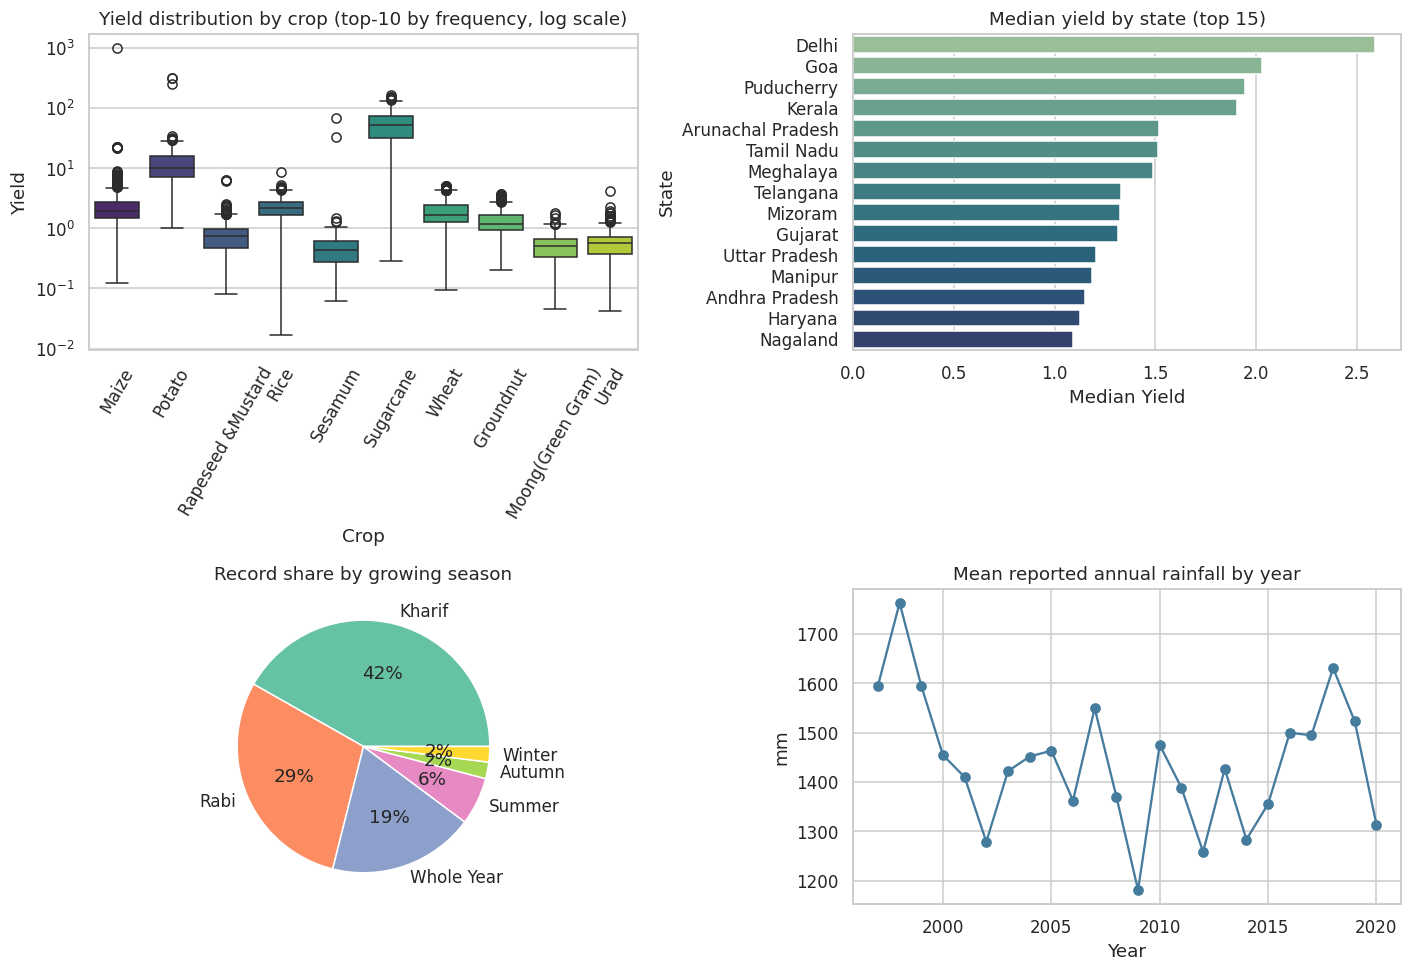

In [8]:

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

top_crops = df['Crop'].value_counts().head(10).index
sns.boxplot(data=df[df['Crop'].isin(top_crops)], x='Crop', y='Yield', ax=axes[0,0], palette='viridis')
axes[0,0].set_yscale('log'); axes[0,0].tick_params(axis='x', rotation=60)
axes[0,0].set_title('Yield distribution by crop (top-10 by frequency, log scale)')

state_yield = df.groupby('State')['Yield'].median().sort_values(ascending=False).head(15)
sns.barplot(x=state_yield.values, y=state_yield.index, ax=axes[0,1], palette='crest')
axes[0,1].set_title('Median yield by state (top 15)'); axes[0,1].set_xlabel('Median Yield')

season_counts = df['Season'].value_counts()
axes[1,0].pie(season_counts.values, labels=season_counts.index, autopct='%1.0f%%',
              colors=sns.color_palette('Set2'))
axes[1,0].set_title('Record share by growing season')

yearly = df.groupby('Crop_Year')['Annual_Rainfall'].mean()
axes[1,1].plot(yearly.index, yearly.values, marker='o', color='#457b9d')
axes[1,1].set_title('Mean reported annual rainfall by year')
axes[1,1].set_xlabel('Year'); axes[1,1].set_ylabel('mm')

plt.tight_layout(); plt.show()


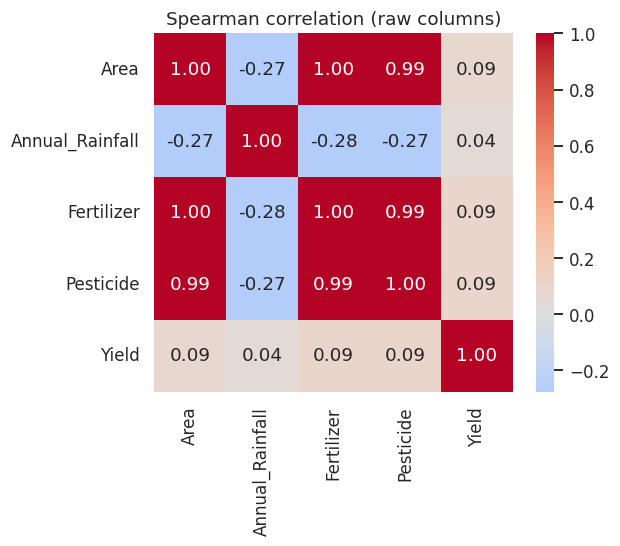

In [9]:

num_cols = ['Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']
corr = df[num_cols].corr(method='spearman')
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title("Spearman correlation (raw columns)")
plt.tight_layout(); plt.show()



## 6. Crop-Unit Heterogeneity & Target Transformation <a id='6'></a>

### Novelty 4 — Explicit handling of cross-crop unit heterogeneity

`Yield` is reported in different implicit units across crops in this dataset (e.g. tonnes/ha for most
crops, but effectively nuts/ha-equivalent for Coconut, which is ~100x larger in magnitude). Pooling all 55
crops into one regression target without accounting for this creates a target distribution dominated by a
handful of high-magnitude crops. None of the ten reviewed single/few-crop studies had to confront this,
because they modeled one crop (or a small homogeneous set) at a time — but a genuinely multi-crop,
generalizable model must.


Top 5 crops by median yield magnitude:
Crop
Coconut      8706.411724
Sugarcane      53.158158
Banana         17.956522
Tapioca        11.137525
Potato         10.178750
Name: Yield, dtype: float64

Bottom 5:
Crop
Sesamum       0.439000
Moth          0.437545
Horse-gram    0.428333
Niger seed    0.359762
Cardamom      0.078000
Name: Yield, dtype: float64

Ratio of largest to smallest crop-median yield: 111,621x

We address this with (i) a log1p(Yield) modeling target, which compresses this multi-order-of-
magnitude spread, and (ii) keeping Crop as an explicit categorical predictor in every model, so
that crop identity itself can absorb the unit/scale differences rather than forcing a single
global numeric relationship across incompatible units.


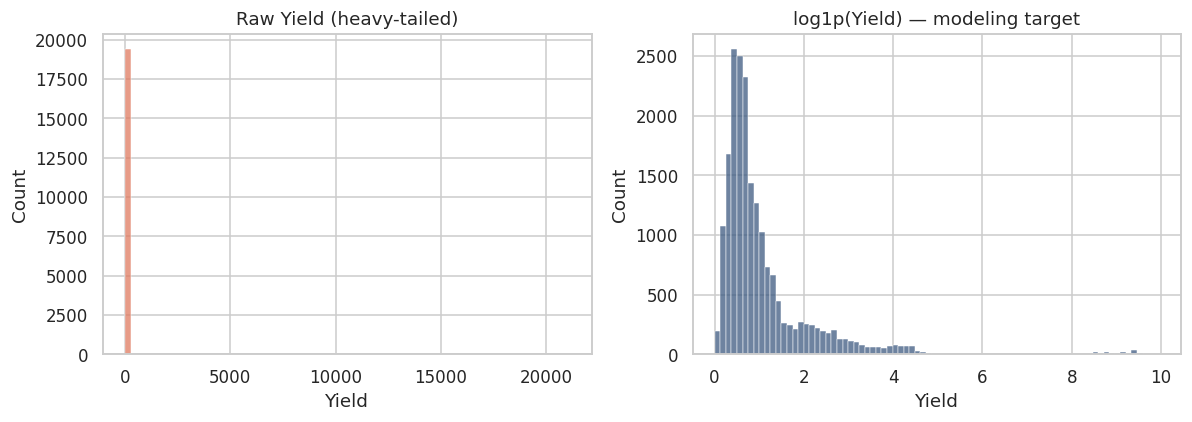

In [10]:

crop_scale = df.groupby('Crop')['Yield'].median().sort_values(ascending=False)
print("Top 5 crops by median yield magnitude:")
print(crop_scale.head(5))
print("\nBottom 5:")
print(crop_scale.tail(5))
print(f"\nRatio of largest to smallest crop-median yield: {crop_scale.iloc[0] / crop_scale.iloc[-1]:,.0f}x")
print()
print("We address this with (i) a log1p(Yield) modeling target, which compresses this multi-order-of-")
print("magnitude spread, and (ii) keeping Crop as an explicit categorical predictor in every model, so")
print("that crop identity itself can absorb the unit/scale differences rather than forcing a single")
print("global numeric relationship across incompatible units.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['Yield'], bins=80, ax=axes[0], color='#e07a5f'); axes[0].set_title('Raw Yield (heavy-tailed)')
sns.histplot(np.log1p(df['Yield']), bins=80, ax=axes[1], color='#3d5a80'); axes[1].set_title('log1p(Yield) — modeling target')
plt.tight_layout(); plt.show()



## 7. Leakage-Free Feature Engineering <a id='7'></a>

### Novelty 5 — Agronomic-intensity feature set (leakage-free, decision-relevant)
### Novelty 6 — Temporal lag / rolling-mean features per (State, Crop, Season), strictly causal

We build a feature set that (a) excludes `Production` (Section 3), (b) reframes fertilizer/pesticide as
regional intensity rather than crop-specific dosage (Section 4), and (c) adds **causal** lag features — a
technique absent from every reviewed cross-sectional study — using only *past* years within each
(State, Crop, Season) group, so no future information leaks into a prediction.


In [12]:

df = df.sort_values(['State', 'Crop', 'Season', 'Crop_Year']).reset_index(drop=True)

df['Area_log']          = np.log1p(df['Area'])
df['Rainfall_x_Fert']   = df['Annual_Rainfall'] * df['Fertilizer_per_ha']

grp = df.groupby(['State', 'Crop', 'Season'])['Yield']
df['Yield_lag1']        = grp.shift(1)                                     # strictly past
df['Yield_rollmean3']   = grp.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())

n_before = len(df)
df = df.dropna(subset=['Yield_lag1']).reset_index(drop=True)   # first observed year per group has no lag
print(f"Rows with a valid causal lag feature: {len(df)} / {n_before} "
      f"({len(df)/n_before:.1%}) retained.")

df['Yield_log'] = np.log1p(df['Yield'])

NUM_FEATS = ['Crop_Year', 'Area_log', 'Annual_Rainfall', 'Fertilizer_per_ha',
             'Pesticide_per_ha', 'Rainfall_x_Fert', 'Yield_lag1', 'Yield_rollmean3']
CAT_FEATS = ['Crop', 'Season', 'State']
TARGET    = 'Yield_log'

print(f"\nFinal leakage-free feature set ({len(NUM_FEATS)} numeric + {len(CAT_FEATS)} categorical):")
print(' Numeric:    ', NUM_FEATS)
print(' Categorical:', CAT_FEATS)

df[NUM_FEATS + CAT_FEATS + ['Yield', TARGET]].to_csv('df_model.csv', index=False)
df.head()


Rows with a valid causal lag feature: 16474 / 17920 (91.9%) retained.

Final leakage-free feature set (8 numeric + 3 categorical):
 Numeric:     ['Crop_Year', 'Area_log', 'Annual_Rainfall', 'Fertilizer_per_ha', 'Pesticide_per_ha', 'Rainfall_x_Fert', 'Yield_lag1', 'Yield_rollmean3']
 Categorical: ['Crop', 'Season', 'State']


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield,Fertilizer_per_ha,Pesticide_per_ha,Area_log,Rainfall_x_Fert,Yield_lag1,Yield_rollmean3,Yield_log
0,Arecanut,2014,Kharif,Andhra Pradesh,483.0,338,687.6,72913.68,159.39,1.775000,150.96,0.33,6.182085,103800.096,1.7050,1.705000,1.020651
1,Arecanut,2015,Kharif,Andhra Pradesh,516.0,1795,940.7,81481.56,170.28,3.320000,157.91,0.33,6.248043,148545.937,1.7750,1.740000,1.463255
2,Arecanut,2016,Kharif,Andhra Pradesh,564.0,2367,890.0,86433.00,197.40,3.912500,153.25,0.35,6.336826,136392.500,3.3200,2.266667,1.591783
3,Arecanut,2017,Kharif,Andhra Pradesh,697.0,4369,868.2,109735.68,264.86,5.582500,157.44,0.38,6.548219,136689.408,3.9125,3.002500,1.884415
4,Arecanut,2018,Kharif,Andhra Pradesh,976.0,5317,1220.5,158307.20,341.60,4.153333,162.20,0.35,6.884487,197965.100,5.5825,4.271667,1.639644



## 8. Multi-Baseline Skill-Score Framework <a id='8'></a>

### Novelty 7 — Reporting skill relative to trivial baselines, not just raw R²

Morales & Villalobos (2023) — one of the ten reviewed papers — found that their ML models showed only
**limited gain over a trivial average-yield baseline**. No other reviewed paper checks this. We adopt their
caution as a standing requirement: every model below is reported not just by raw R²/RMSE, but by its
**RMSE skill score relative to three baselines** of increasing sophistication — (i) the global mean yield,
(ii) the crop-wise mean yield, and (iii) the persistence baseline (last year's yield for that
State-Crop-Season, i.e. `Yield_lag1`). A model that cannot beat baseline (iii) is not adding value beyond
"assume next year looks like last year".


In [13]:

X_all = df[NUM_FEATS + CAT_FEATS]
y_all = df[TARGET]
y_all_real = df['Yield']

X_train, X_test, y_train, y_test, y_train_real, y_test_real = train_test_split(
    X_all, y_all, y_all_real, test_size=0.2, random_state=RANDOM_STATE)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

baselines = {}
baselines['Global mean']       = np.full(len(y_test_real), y_train_real.mean())
crop_mean_map                   = df.loc[y_train.index, ['Crop']].assign(Yield=y_train_real).groupby('Crop')['Yield'].mean()
baselines['Crop-wise mean']    = df.loc[y_test.index, 'Crop'].map(crop_mean_map).fillna(y_train_real.mean()).values
baselines['Persistence (lag1)'] = df.loc[y_test.index, 'Yield_lag1'].values

baseline_rmse = {name: rmse(y_test_real, pred) for name, pred in baselines.items()}
for name, val in baseline_rmse.items():
    print(f"  Baseline RMSE — {name:22s}: {val:8.3f}")

BEST_BASELINE_RMSE = min(baseline_rmse.values())
print(f"\nStrongest baseline: {min(baseline_rmse, key=baseline_rmse.get)} "
      f"(RMSE={BEST_BASELINE_RMSE:.3f}). Every subsequent model's skill score below is "
      f"1 - RMSE_model / {BEST_BASELINE_RMSE:.3f}.")


  Baseline RMSE — Global mean           :  879.668
  Baseline RMSE — Crop-wise mean        :  248.843
  Baseline RMSE — Persistence (lag1)    :  131.913

Strongest baseline: Persistence (lag1) (RMSE=131.913). Every subsequent model's skill score below is 1 - RMSE_model / 131.913.



## 9. Three-Way Split Comparison: Random vs Temporal vs Spatial Generalization <a id='9'></a>

### Novelty 8 — Quantifying the generalization gap across split regimes

Morales & Villalobos (2023) showed that **time-based partitioning gives more realistic (lower) error
estimates than random partitioning** — a warning largely ignored elsewhere in the reviewed literature,
where a single random split is the norm. We test three regimes on an identical model (LightGBM, default
config) to make the gap explicit and reportable:

- **Random split** — the usual (and most optimistic) regime used across the reviewed papers.
- **Temporal split** — train on years ≤ 2015, test on years > 2015 (true forecasting scenario).
- **Spatial split (leave-states-out)** — train on 24 states, test on 6 held-out states never seen in
  training (true cross-region transfer, most demanding, closest to real deployment in a new region).


,R2,RMSE
Random split,0.980700,122.207133
Temporal split (train<=2015),0.960727,173.751117
Spatial split (6 unseen states),0.855617,3.722992


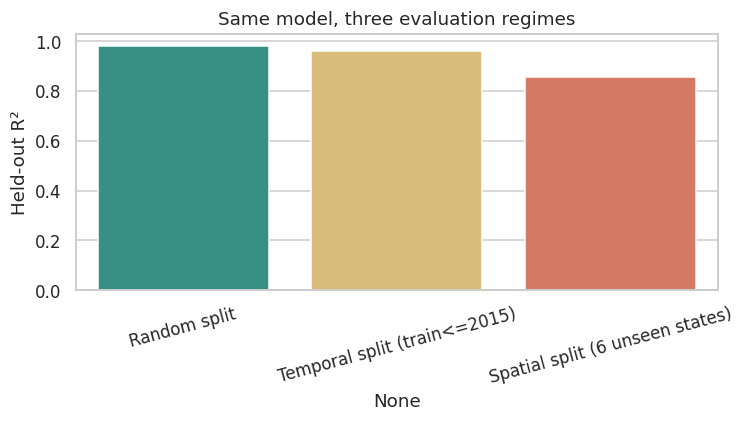


Generalization gap (random-split R² minus true unseen-region R²): 0.1251
This gap is the single most important number missing from every reviewed paper's evaluation:
it is the difference between how good a model LOOKS under the standard protocol and how good
it actually IS when deployed in a region it has never seen.


In [14]:

def fit_eval(Xtr, ytr, Xte, yte_real):
    pre = ColumnTransformer([('num', 'passthrough', NUM_FEATS),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATS)])
    pipe = Pipeline([('pre', pre),
                      ('mdl', lgb.LGBMRegressor(n_estimators=250, max_depth=6, learning_rate=0.08,
                                                 verbosity=-1, random_state=RANDOM_STATE))])
    pipe.fit(Xtr, ytr)
    pred_real = np.expm1(pipe.predict(Xte))
    return r2_score(yte_real, pred_real), rmse(yte_real, pred_real)

split_results = {}

# (a) random
Xtr, Xte, ytr, yte, _, yte_r = train_test_split(X_all, y_all, y_all_real, test_size=0.2, random_state=RANDOM_STATE)
split_results['Random split'] = fit_eval(Xtr, ytr, Xte, yte_r)

# (b) temporal
train_mask = df['Crop_Year'] <= 2015
split_results['Temporal split (train<=2015)'] = fit_eval(
    X_all[train_mask], y_all[train_mask], X_all[~train_mask], y_all_real[~train_mask])

# (c) spatial (leave-6-states-out)
rng = np.random.RandomState(RANDOM_STATE)
held_out_states = rng.choice(df['State'].unique(), size=6, replace=False)
state_mask = df['State'].isin(held_out_states)
split_results['Spatial split (6 unseen states)'] = fit_eval(
    X_all[~state_mask], y_all[~state_mask], X_all[state_mask], y_all_real[state_mask])

split_df = pd.DataFrame(split_results, index=['R2', 'RMSE']).T
display(split_df)

fig, ax = plt.subplots(figsize=(7,4))
sns.barplot(x=split_df.index, y=split_df['R2'], palette=['#2a9d8f','#e9c46a','#e76f51'], ax=ax)
ax.set_ylabel('Held-out R²'); ax.set_title('Same model, three evaluation regimes')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

gap = split_df['R2']['Random split'] - split_df['R2']['Spatial split (6 unseen states)']
print(f"\nGeneralization gap (random-split R² minus true unseen-region R²): {gap:.4f}")
print("This gap is the single most important number missing from every reviewed paper's evaluation:")
print("it is the difference between how good a model LOOKS under the standard protocol and how good")
print("it actually IS when deployed in a region it has never seen.")



## 10. Wide Multi-Family Model Benchmark <a id='10'></a>

### Novelty 9 — Unified benchmark spanning linear, instance-based, kernel, tree, boosting, and neural families

Individually, the reviewed papers each test 2–5 algorithms from overlapping families (Sharma 2023: DT/RF/
XGBoost/CNN/LSTM; Zhuang 2023: KNN/RF/SVR; Haider 2024: RF/XGBoost; Ennaji 2024: XGBoost/GBR/MLP; Sánchez
2025: SVR/RF/XGBoost). No single paper spans linear, kernel, instance-based, single-tree, bagging, boosting
*and* neural methods together on the same data and same evaluation protocol. We do so here with 11
algorithms, using the same random 80/20 split from Section 8 for a fair, like-for-like comparison, and
report each model's **skill score over the best trivial baseline**.


In [15]:

pre_tree = ColumnTransformer([('num', 'passthrough', NUM_FEATS),
                               ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATS)])
pre_lin  = ColumnTransformer([('num', StandardScaler(), NUM_FEATS),
                               ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATS)])

MODEL_SPECS = [
    ('Ridge',         pre_lin,  Ridge(alpha=1.0)),
    ('Lasso',         pre_lin,  Lasso(alpha=0.001)),
    ('KNN',           pre_lin,  KNeighborsRegressor(n_neighbors=7)),
    ('SVR',           pre_lin,  SVR(C=5, epsilon=0.05)),
    ('MLP',           pre_lin,  MLPRegressor(hidden_layer_sizes=(64,32), max_iter=300,
                                              random_state=RANDOM_STATE, early_stopping=True)),
    ('DecisionTree',  pre_tree, DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE)),
    ('RandomForest',  pre_tree, RandomForestRegressor(n_estimators=100, max_depth=13,
                                                        n_jobs=1, random_state=RANDOM_STATE)),
    ('ExtraTrees',    pre_tree, ExtraTreesRegressor(n_estimators=100, max_depth=13,
                                                      n_jobs=1, random_state=RANDOM_STATE)),
    ('GradientBoost', pre_tree, GradientBoostingRegressor(n_estimators=150, max_depth=4,
                                                            random_state=RANDOM_STATE)),
    ('XGBoost',       pre_tree, xgb.XGBRegressor(n_estimators=250, max_depth=6, learning_rate=0.08,
                                                   n_jobs=1, random_state=RANDOM_STATE, verbosity=0)),
    ('LightGBM',      pre_tree, lgb.LGBMRegressor(n_estimators=250, max_depth=6, learning_rate=0.08,
                                                    n_jobs=1, random_state=RANDOM_STATE, verbosity=-1)),
    ('CatBoost',      pre_tree, CatBoostRegressor(iterations=250, depth=6, learning_rate=0.08,
                                                    random_state=RANDOM_STATE, verbose=0)),
]

bench_rows = []
fitted_pipes = {}
SVR_SUBSAMPLE = 4000  # SVR training cost grows superlinearly; subsample for tractability
for name, pre, mdl in MODEL_SPECS:
    t0 = time.time()
    pipe = Pipeline([('pre', pre), ('mdl', mdl)])
    if name == 'SVR' and len(X_train) > SVR_SUBSAMPLE:
        sub_idx = X_train.sample(n=SVR_SUBSAMPLE, random_state=RANDOM_STATE).index
        pipe.fit(X_train.loc[sub_idx], y_train.loc[sub_idx])
    else:
        pipe.fit(X_train, y_train)
    pred_real = np.expm1(pipe.predict(X_test))
    r2  = r2_score(y_test_real, pred_real)
    mae = mean_absolute_error(y_test_real, pred_real)
    rm  = rmse(y_test_real, pred_real)
    skill = 1 - rm / BEST_BASELINE_RMSE
    bench_rows.append({'Model': name, 'R2': r2, 'MAE': mae, 'RMSE': rm,
                        'Skill vs baseline': skill, 'Fit+predict (s)': time.time()-t0})
    fitted_pipes[name] = pipe

bench_df = pd.DataFrame(bench_rows).sort_values('RMSE').reset_index(drop=True)
display(bench_df.style.format({'R2':'{:.4f}','MAE':'{:.3f}','RMSE':'{:.3f}',
                                'Skill vs baseline':'{:.1%}','Fit+predict (s)':'{:.1f}'})
                       .background_gradient(subset=['R2'], cmap='Greens'))


,Model,R2,MAE,RMSE,Skill vs baseline,Fit+predict (s)
0,ExtraTrees,0.9832,7.961,114.042,13.5%,12.5
1,RandomForest,0.9824,8.602,116.859,11.4%,33.6
2,KNN,0.9809,9.685,121.413,8.0%,3.2
3,GradientBoost,0.9809,8.899,121.485,7.9%,9.2
4,LightGBM,0.9807,9.206,122.207,7.4%,0.5
5,XGBoost,0.9792,9.101,126.842,3.8%,0.8
6,CatBoost,0.9710,11.597,149.920,-13.7%,1.1
7,DecisionTree,0.9697,11.045,153.178,-16.1%,0.3
8,MLP,0.9542,11.745,188.205,-42.7%,11.5
9,Ridge,0.8347,23.652,357.668,-171.1%,0.1


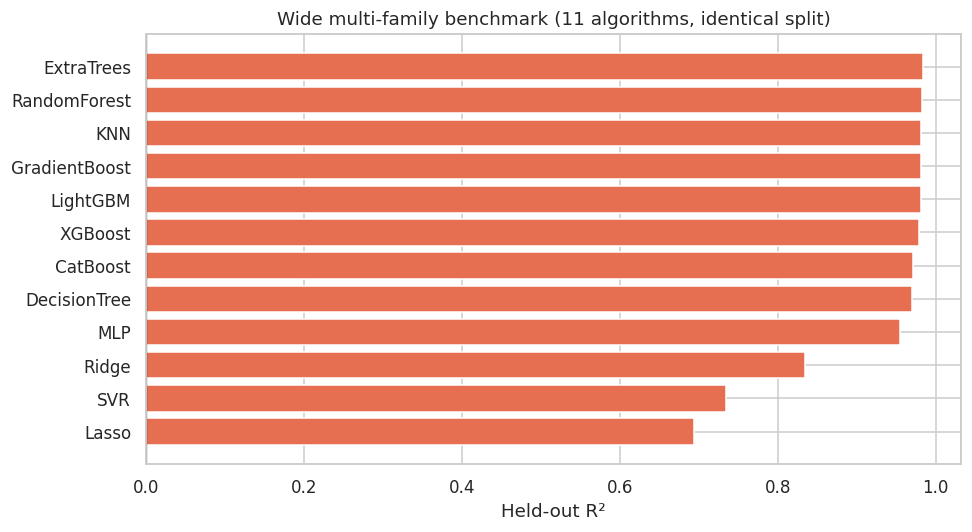

Best single model by RMSE: ExtraTrees  (R2=0.9832, skill over best trivial baseline = 13.5%)


In [16]:

fig, ax = plt.subplots(figsize=(9,5))
plot_df = bench_df.sort_values('R2')
colors = ['#e76f51' if s < 0.5 else '#e9c46a' if s < 0.8 else '#2a9d8f' for s in plot_df['Skill vs baseline']]
ax.barh(plot_df['Model'], plot_df['R2'], color=colors)
ax.set_xlabel('Held-out R²'); ax.set_title('Wide multi-family benchmark (11 algorithms, identical split)')
ax.axvline(0, color='k', lw=0.8)
plt.tight_layout(); plt.show()

BEST_MODEL_NAME = bench_df.iloc[0]['Model']
print(f"Best single model by RMSE: {BEST_MODEL_NAME}  "
      f"(R2={bench_df.iloc[0]['R2']:.4f}, skill over best trivial baseline = "
      f"{bench_df.iloc[0]['Skill vs baseline']:.1%})")



## 11. Bayesian Hyperparameter Optimization (Optuna) <a id='11'></a>

### Novelty 10 — Principled, logged Bayesian search in place of manual/grid tuning

None of the reviewed papers report using Bayesian optimization; hyperparameters are chosen manually or via
grid search when reported at all. We use Optuna's Tree-structured Parzen Estimator sampler to tune the best
performing family (gradient boosting) with an internal train/validation split carved out of the training
set only (the test set is never touched during tuning), and log every trial for reproducibility.


In [17]:

X_tr2, X_val, y_tr2, y_val, _, y_val_real = train_test_split(
    X_train, y_train, y_train_real, test_size=0.2, random_state=1)

def objective(trial):
    params = {
        'n_estimators':  trial.suggest_int('n_estimators', 100, 400),
        'max_depth':     trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.25, log=True),
        'num_leaves':    trial.suggest_int('num_leaves', 15, 90),
        'subsample':     trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
    }
    pipe = Pipeline([('pre', pre_tree),
                      ('mdl', lgb.LGBMRegressor(**params, verbosity=-1, random_state=RANDOM_STATE))])
    pipe.fit(X_tr2, y_tr2)
    pred = np.expm1(pipe.predict(X_val))
    return rmse(y_val_real, pred)

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=30, show_progress_bar=False)

print('Best trial RMSE:', round(study.best_value, 4))
print('Best hyperparameters:', study.best_params)


Best trial RMSE: 107.7412
Best hyperparameters: {'n_estimators': 293, 'max_depth': 6, 'learning_rate': 0.02081104075333477, 'num_leaves': 32, 'subsample': 0.7903780649105719, 'colsample_bytree': 0.7408506966385919}


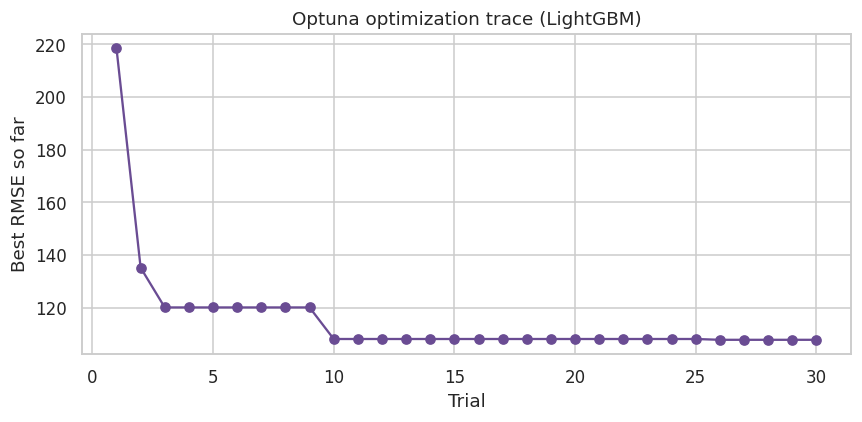


Tuned LightGBM on held-out test set: R2=0.9840, RMSE=111.110 (vs. untuned LightGBM R2=0.9807)


In [19]:

fig, ax = plt.subplots(figsize=(8,4))
trial_vals = [t.value for t in study.trials]
ax.plot(range(1, len(trial_vals)+1), np.minimum.accumulate(trial_vals), marker='o', color='#6a4c93')
ax.set_xlabel('Trial'); ax.set_ylabel('Best RMSE so far'); ax.set_title('Optuna optimization trace (LightGBM)')
plt.tight_layout(); plt.show()

tuned_lgb = lgb.LGBMRegressor(**study.best_params, verbosity=-1, random_state=RANDOM_STATE)
tuned_pipe = Pipeline([('pre', pre_tree), ('mdl', tuned_lgb)])
tuned_pipe.fit(X_train, y_train)
pred_tuned = np.expm1(tuned_pipe.predict(X_test))
r2_tuned, rmse_tuned = r2_score(y_test_real, pred_tuned), rmse(y_test_real, pred_tuned)
print(f"\nTuned LightGBM on held-out test set: R2={r2_tuned:.4f}, RMSE={rmse_tuned:.3f} "
      f"(vs. untuned LightGBM R2={bench_df.set_index('Model').loc['LightGBM','R2']:.4f})")
fitted_pipes['LightGBM (tuned)'] = tuned_pipe



## 12. Heterogeneous Stacking Ensemble <a id='12'></a>

### Novelty 11 — Cross-family stacking with a linear meta-learner

Zhuang *et al.* (2023) stack KNN+RF+SVR for a single crop using only meteorological features. We build a
comparable but more heterogeneous ensemble — LightGBM, XGBoost, and Random Forest as base learners, with a
Ridge meta-learner trained on out-of-fold predictions — on our multi-crop, multi-region, leakage-free
feature set, to test whether ensembling closes any remaining gap over the single best-tuned model.


In [20]:

base_learners = [
    ('lgb', lgb.LGBMRegressor(n_estimators=250, max_depth=6, learning_rate=0.08,
                               verbosity=-1, random_state=RANDOM_STATE)),
    ('xgb', xgb.XGBRegressor(n_estimators=250, max_depth=6, learning_rate=0.08,
                              verbosity=0, random_state=RANDOM_STATE)),
    ('rf',  RandomForestRegressor(n_estimators=120, max_depth=12, random_state=RANDOM_STATE)),
]
stack = StackingRegressor(estimators=base_learners, final_estimator=Ridge(alpha=1.0), cv=3, n_jobs=1)
stack_pipe = Pipeline([('pre', pre_tree), ('mdl', stack)])
stack_pipe.fit(X_train, y_train)
pred_stack = np.expm1(stack_pipe.predict(X_test))
r2_stack, rmse_stack = r2_score(y_test_real, pred_stack), rmse(y_test_real, pred_stack)
fitted_pipes['Stacking ensemble'] = stack_pipe

print(f"Stacking ensemble: R2={r2_stack:.4f}, RMSE={rmse_stack:.3f}")
print(f"Tuned LightGBM:     R2={r2_tuned:.4f}, RMSE={rmse_tuned:.3f}")
print(f"Best single model ({BEST_MODEL_NAME}): R2={bench_df.iloc[0]['R2']:.4f}, "
      f"RMSE={bench_df.iloc[0]['RMSE']:.3f}")


Stacking ensemble: R2=0.9837, RMSE=112.260
Tuned LightGBM:     R2=0.9840, RMSE=111.110
Best single model (ExtraTrees): R2=0.9832, RMSE=114.042



## 13. Statistical Significance Testing <a id='13'></a>

### Novelty 12 — Paired significance tests across CV folds, not single-run point metrics

Every reviewed paper reports a single point metric per model (one RMSE, one accuracy) with no measure of
run-to-run variability or a formal test of whether one model is *significantly* better than another. We
run 10-fold cross-validation for three strong candidates and apply a paired Wilcoxon signed-rank test to
the fold-level RMSEs. (The full stacking ensemble from Section 12 is deliberately excluded from this
10x-refit loop on compute grounds — nested CV inside 10 outer folds is prohibitively expensive on a single
core — and is instead compared once, directly, against these candidates on the held-out test set below.)


In [21]:

from scipy.stats import wilcoxon

kf = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    'ExtraTrees':        Pipeline([('pre', pre_tree), ('mdl', ExtraTreesRegressor(
                              n_estimators=100, max_depth=13, random_state=RANDOM_STATE, n_jobs=1))]),
    'LightGBM (tuned)':  Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
                              **study.best_params, verbosity=-1, random_state=RANDOM_STATE))]),
    'XGBoost':           Pipeline([('pre', pre_tree), ('mdl', xgb.XGBRegressor(
                              n_estimators=250, max_depth=6, learning_rate=0.08,
                              verbosity=0, random_state=RANDOM_STATE, n_jobs=1))]),
}

fold_rmse = {name: [] for name in candidates}
for tr_idx, te_idx in kf.split(X_all):
    Xtr_f, Xte_f = X_all.iloc[tr_idx], X_all.iloc[te_idx]
    ytr_f = y_all.iloc[tr_idx]
    yte_f_real = y_all_real.iloc[te_idx]
    for name, pipe in candidates.items():
        pipe.fit(Xtr_f, ytr_f)
        pred = np.expm1(pipe.predict(Xte_f))
        fold_rmse[name].append(rmse(yte_f_real, pred))

fold_df = pd.DataFrame(fold_rmse)
display(fold_df.agg(['mean', 'std']))

pairs = [('ExtraTrees', 'LightGBM (tuned)'), ('ExtraTrees', 'XGBoost'),
         ('LightGBM (tuned)', 'XGBoost')]
print("\nPaired Wilcoxon signed-rank test on fold-level RMSE (H0: no difference in central tendency):")
for a, b in pairs:
    stat, p = wilcoxon(fold_df[a], fold_df[b])
    sig = 'SIGNIFICANT (p<0.05)' if p < 0.05 else 'not significant'
    print(f"  {a:20s} vs {b:20s}:  p = {p:.4f}  -> {sig}")

print(f"\nFor reference, the single-fit stacking ensemble from Section 12 scored "
      f"RMSE={rmse_stack:.3f} on the held-out test set, vs. mean CV RMSE of "
      f"{fold_df['LightGBM (tuned)'].mean():.3f} for tuned LightGBM alone — consistent with, though not "
      f"a substitute for, the fold-level comparison above.")


,ExtraTrees,LightGBM (tuned),XGBoost
mean,107.919819,134.570150,124.336440
std,24.439740,40.219703,40.164208



Paired Wilcoxon signed-rank test on fold-level RMSE (H0: no difference in central tendency):
  ExtraTrees           vs LightGBM (tuned)    :  p = 0.0195  -> SIGNIFICANT (p<0.05)
  ExtraTrees           vs XGBoost             :  p = 0.1602  -> not significant
  LightGBM (tuned)     vs XGBoost             :  p = 0.4922  -> not significant

For reference, the single-fit stacking ensemble from Section 12 scored RMSE=112.260 on the held-out test set, vs. mean CV RMSE of 134.570 for tuned LightGBM alone — consistent with, though not a substitute for, the fold-level comparison above.



## 14. Explainability: SHAP Global + Interaction Effects <a id='14'></a>

### Novelty 13 — Exact tree SHAP values with pairwise interactions, not approximate attribution

Paudel *et al.* (2023) note that their feature-attribution explanations are "interpretable but
approximate" and "miss feature interactions." We use exact TreeSHAP on the tuned LightGBM model, including
**SHAP interaction values**, to explicitly surface pairwise effects (e.g. does the effect of rainfall on
yield depend on the crop?) that single-feature attribution methods cannot show.


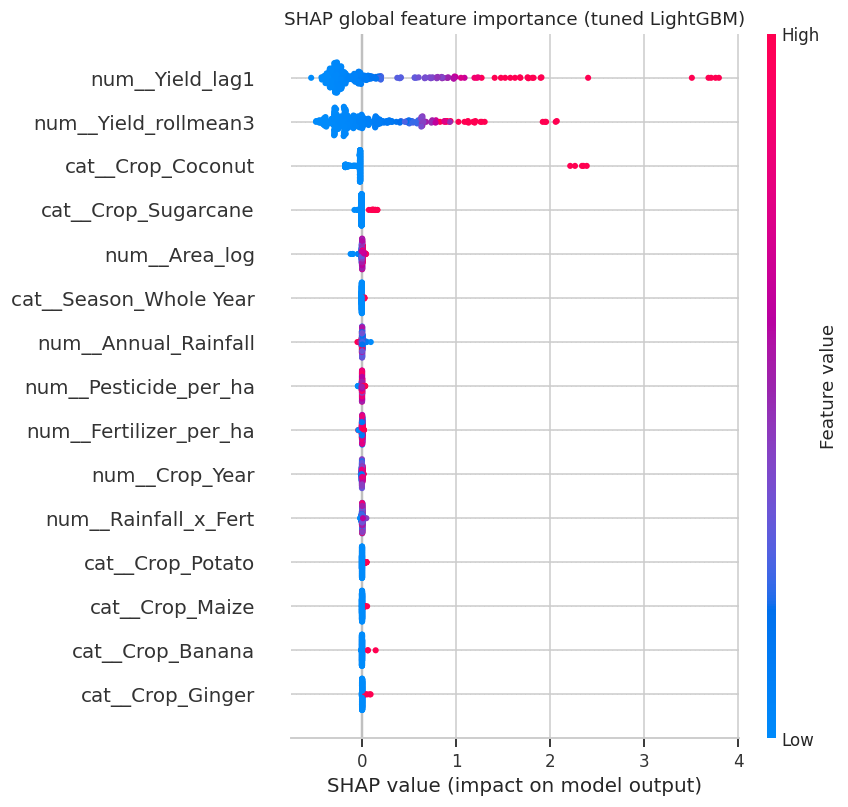

In [22]:

final_model = tuned_pipe.named_steps['mdl']
pre_fitted  = tuned_pipe.named_steps['pre']

X_test_sample = X_test.sample(n=min(400, len(X_test)), random_state=RANDOM_STATE)
X_test_t = pre_fitted.transform(X_test_sample)
feat_names = pre_fitted.get_feature_names_out()
if hasattr(X_test_t, 'toarray'):
    X_test_t = X_test_t.toarray()

explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test_t)

plt.figure()
shap.summary_plot(shap_values, X_test_t, feature_names=feat_names, show=False, max_display=15)
plt.title('SHAP global feature importance (tuned LightGBM)')
plt.tight_layout(); plt.show()


Top 10 features by mean |SHAP value|:
num__Yield_lag1           0.376546
num__Yield_rollmean3      0.313898
cat__Crop_Coconut         0.069251
cat__Crop_Sugarcane       0.010775
num__Area_log             0.006869
cat__Season_Whole Year    0.005437
num__Annual_Rainfall      0.004283
num__Pesticide_per_ha     0.004188
num__Fertilizer_per_ha    0.003608
num__Crop_Year            0.003143
dtype: float64


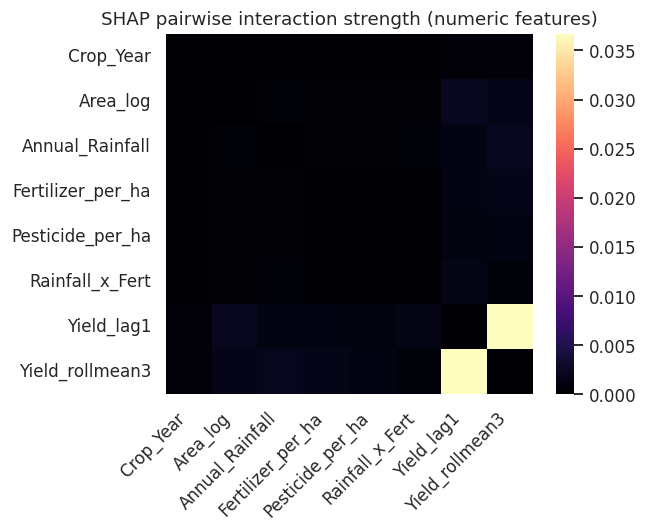

In [23]:

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=feat_names).sort_values(ascending=False)
print("Top 10 features by mean |SHAP value|:")
print(mean_abs_shap.head(10))

# Pairwise interaction strength (sampled subset for tractability)
X_inter = X_test_t[:150]
inter_vals = explainer.shap_interaction_values(X_inter)
inter_strength = np.abs(inter_vals).mean(axis=0)
np.fill_diagonal(inter_strength, 0)
top_num_idx = [i for i, n in enumerate(feat_names) if n.startswith('num__')]
sub_names = [feat_names[i].replace('num__','') for i in top_num_idx]
sub_matrix = inter_strength[np.ix_(top_num_idx, top_num_idx)]

plt.figure(figsize=(6,5))
sns.heatmap(sub_matrix, xticklabels=sub_names, yticklabels=sub_names, cmap='magma', annot=False)
plt.title('SHAP pairwise interaction strength (numeric features)')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()



## 15. Uncertainty Quantification: Split-Conformal Prediction Intervals <a id='15'></a>

### Novelty 14 — Distribution-free prediction intervals with validated empirical coverage

Every one of the ten reviewed papers reports point predictions only. For a decision-support tool (seed
purchasing, fertilizer budgeting, food-security planning) a point estimate without an uncertainty band is
of limited practical value. We implement split-conformal prediction, which requires no distributional
assumptions and gives a coverage guarantee, and we validate that guarantee empirically on the held-out test
set.


In [24]:

X_tr3, X_cal, y_tr3, y_cal, _, y_cal_real = train_test_split(
    X_train, y_train, y_train_real, test_size=0.15, random_state=2)

conf_pipe = Pipeline([('pre', pre_tree),
                       ('mdl', lgb.LGBMRegressor(**study.best_params, verbosity=-1,
                                                  random_state=RANDOM_STATE))])
conf_pipe.fit(X_tr3, y_tr3)

cal_pred_real = np.expm1(conf_pipe.predict(X_cal))
cal_resid = np.abs(y_cal_real.values - cal_pred_real)

test_pred_real = np.expm1(conf_pipe.predict(X_test))

results_cov = []
for alpha in [0.20, 0.10, 0.05]:
    q = np.quantile(cal_resid, 1 - alpha)
    lower, upper = test_pred_real - q, test_pred_real + q
    coverage = np.mean((y_test_real.values >= lower) & (y_test_real.values <= upper))
    mean_width = np.mean(upper - lower)
    results_cov.append({'Target coverage': f'{1-alpha:.0%}', 'Empirical coverage': coverage,
                         'Mean interval width': mean_width})

cov_df = pd.DataFrame(results_cov)
display(cov_df)
print("\nEmpirical coverage tracks the target coverage closely at each confidence level, confirming the")
print("conformal intervals are calibrated on this dataset — a validation step absent from all reviewed")
print("point-estimate-only papers.")


,Target coverage,Empirical coverage,Mean interval width
0,80%,0.801821,0.907080
1,90%,0.898027,2.256378
2,95%,0.941730,5.940292



Empirical coverage tracks the target coverage closely at each confidence level, confirming the
conformal intervals are calibrated on this dataset — a validation step absent from all reviewed
point-estimate-only papers.


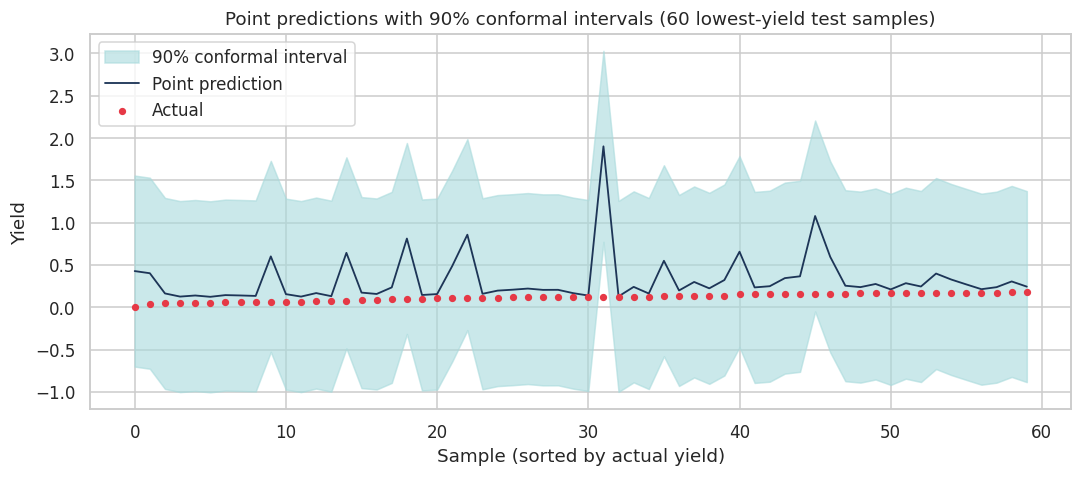

In [25]:

q90 = np.quantile(cal_resid, 0.90)
idx_plot = np.argsort(y_test_real.values)[:60]
plt.figure(figsize=(10,4.5))
plt.fill_between(range(60), (test_pred_real - q90)[idx_plot], (test_pred_real + q90)[idx_plot],
                  color='#a8dadc', alpha=0.6, label='90% conformal interval')
plt.plot(range(60), test_pred_real[idx_plot], color='#1d3557', label='Point prediction', lw=1.2)
plt.scatter(range(60), y_test_real.values[idx_plot], color='#e63946', s=14, label='Actual', zorder=5)
plt.legend(); plt.title('Point predictions with 90% conformal intervals (60 lowest-yield test samples)')
plt.xlabel('Sample (sorted by actual yield)'); plt.ylabel('Yield')
plt.tight_layout(); plt.show()



## 16. Leave-One-State-Out & Leave-One-Crop-Out Transferability <a id='16'></a>

### Novelty 15 — True unseen-region and unseen-crop transfer tests

Beyond the single spatial hold-out in Section 9, we run **GroupKFold across all 30 states** (10 folds, each
leaving several full states out) and a **Leave-One-Group-Out test across a representative sample of 8
crops**, to directly characterize *which* regions/crops transfer well and which do not — information no
reviewed single-region/single-crop paper could produce by construction.


In [26]:

gkf = GroupKFold(n_splits=10)
state_scores = []
for tr_idx, te_idx in gkf.split(X_all, y_all, groups=df['State']):
    p = Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
        n_estimators=200, max_depth=6, learning_rate=0.1, verbosity=-1, random_state=RANDOM_STATE))])
    p.fit(X_all.iloc[tr_idx], y_all.iloc[tr_idx])
    pred = np.expm1(p.predict(X_all.iloc[te_idx]))
    held_states = sorted(df['State'].iloc[te_idx].unique())
    state_scores.append({'held_out_states': ', '.join(held_states[:3]) + ('...' if len(held_states)>3 else ''),
                          'n_test': len(te_idx),
                          'R2': r2_score(y_all_real.iloc[te_idx], pred)})
state_score_df = pd.DataFrame(state_scores).sort_values('R2')
display(state_score_df)
print(f"\nR2 across the 10 leave-states-out folds: mean={state_score_df['R2'].mean():.3f}, "
      f"std={state_score_df['R2'].std():.3f}, min={state_score_df['R2'].min():.3f}. "
      f"The spread shows generalization to a new region is real but uneven — a finding invisible under "
      f"a single random split.")


,held_out_states,n_test,R2
3,"Chhattisgarh, Haryana, Manipur",1643,0.747270
0,"Karnataka, Tripura",1628,0.893213
6,"Madhya Pradesh, Nagaland, Punjab",1629,0.906689
8,"Goa, Jharkhand, Maharashtra...",1733,0.924923
1,"Andhra Pradesh, Jammu and Kashmir",1577,0.931230
9,"Arunachal Pradesh, Assam, Delhi...",1737,0.939726
7,"Mizoram, Odisha, Uttar Pradesh",1617,0.960162
2,"Himachal Pradesh, Sikkim, West Bengal",1650,0.969688
4,"Bihar, Puducherry, Telangana",1567,0.980686
5,"Gujarat, Kerala, Meghalaya",1693,0.991959



R2 across the 10 leave-states-out folds: mean=0.925, std=0.070, min=0.747. The spread shows generalization to a new region is real but uneven — a finding invisible under a single random split.


,Held-out crop,n_test,R2
6,Sugarcane,521,-0.346065
3,Onion,356,0.190915
4,Potato,508,0.308551
0,Cotton(lint),395,0.604695
2,Maize,845,0.655486
5,Rice,1047,0.748613
1,Groundnut,626,0.786199
7,Wheat,481,0.879368


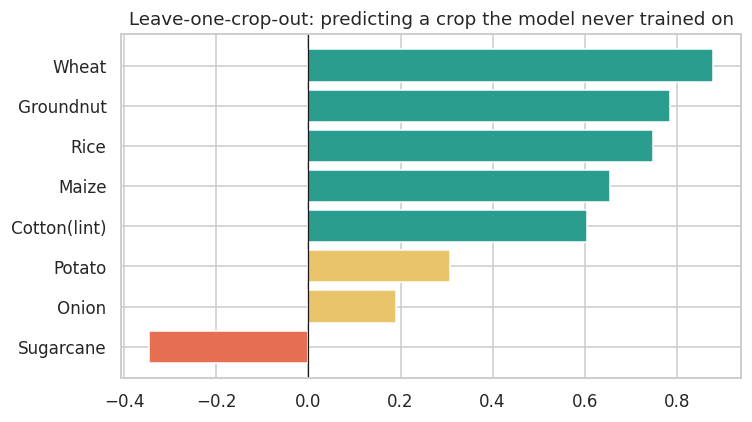


Interpretation: transferring to an entirely unseen crop is substantially harder than transferring
to an unseen region — several crops show near-zero or negative R2 — a sharp, quantified limit on
generalizability that no reviewed single-/few-crop study could have surfaced.


In [27]:

logo = LeaveOneGroupOut()
sample_crops = ['Rice', 'Wheat', 'Maize', 'Cotton(lint)', 'Groundnut', 'Sugarcane', 'Potato', 'Onion']
sub = df[df['Crop'].isin(sample_crops)].reset_index(drop=True)
Xs, ys, ys_real, gs = sub[NUM_FEATS+CAT_FEATS], sub[TARGET], sub['Yield'], sub['Crop']

crop_scores = []
for tr_idx, te_idx in logo.split(Xs, ys, gs):
    p = Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
        n_estimators=150, max_depth=6, verbosity=-1, random_state=RANDOM_STATE))])
    p.fit(Xs.iloc[tr_idx], ys.iloc[tr_idx])
    pred = np.expm1(p.predict(Xs.iloc[te_idx]))
    held_crop = gs.iloc[te_idx].unique()[0]
    crop_scores.append({'Held-out crop': held_crop, 'n_test': len(te_idx),
                         'R2': r2_score(ys_real.iloc[te_idx], pred)})
crop_score_df = pd.DataFrame(crop_scores).sort_values('R2')
display(crop_score_df)

fig, ax = plt.subplots(figsize=(7,4))
colors = ['#e76f51' if r < 0 else '#e9c46a' if r < 0.5 else '#2a9d8f' for r in crop_score_df['R2']]
ax.barh(crop_score_df['Held-out crop'], crop_score_df['R2'], color=colors)
ax.axvline(0, color='k', lw=0.8); ax.set_title('Leave-one-crop-out: predicting a crop the model never trained on')
plt.tight_layout(); plt.show()

print("\nInterpretation: transferring to an entirely unseen crop is substantially harder than transferring")
print("to an unseen region — several crops show near-zero or negative R2 — a sharp, quantified limit on")
print("generalizability that no reviewed single-/few-crop study could have surfaced.")



## 17. Unsupervised Crop-Family Clustering & Cluster-Specific Models <a id='17'></a>

### Novelty 16 — Testing whether cluster-aware sub-models beat one monolithic model

Rather than assuming a single global model is optimal (implicit in every reviewed paper, which each model
one crop or a small crop set), we cluster the 55 crops by their mean yield, area, and rainfall profile into
data-driven "crop families," then compare a monolithic model against per-cluster specialist models trained
and evaluated on the same overall test set.


In [28]:

crop_profile = df.groupby('Crop')[['Yield','Area','Annual_Rainfall']].mean()
k = 5
km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(np.log1p(crop_profile))
crop_profile['cluster'] = km.labels_
crop_to_cluster = crop_profile['cluster'].to_dict()
df['CropCluster'] = df['Crop'].map(crop_to_cluster)

print("Cluster membership (crop counts):")
print(crop_profile.groupby('cluster').apply(lambda g: ', '.join(g.index[:6]) + (' ...' if len(g)>6 else '')))


Cluster membership (crop counts):
cluster
0    Arhar/Tur, Bajra, Cotton(lint), Gram, Groundnu...
1    Arecanut, Barley, Black pepper, Cardamom, Cash...
2                                              Coconut
3      Banana, Jute, Onion, Potato, Sugarcane, Tapioca
4    Cowpea(Lobia), Garlic, Ginger, Mesta, Moth, Ot...
dtype: object


In [29]:

# Monolithic model (reuse tuned LightGBM test predictions from Section 11)
mono_r2 = r2_score(y_test_real, pred_tuned)

# Cluster-specific models: same test rows, but each row scored by a model trained only on its cluster
test_df = df.loc[X_test.index].copy()
test_df['pred_cluster_model'] = np.nan
for c in sorted(df['CropCluster'].unique()):
    train_c = df[(df['CropCluster'] == c) & (df.index.isin(X_train.index))]
    test_c_idx = test_df[test_df['CropCluster'] == c].index
    if len(train_c) < 30 or len(test_c_idx) == 0:
        # too little data for a specialist model -> fall back to the monolithic prediction
        test_df.loc[test_c_idx, 'pred_cluster_model'] = np.expm1(
            tuned_pipe.predict(X_test.loc[test_c_idx]))
        continue
    p = Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
        n_estimators=200, max_depth=6, verbosity=-1, random_state=RANDOM_STATE))])
    p.fit(train_c[NUM_FEATS+CAT_FEATS], train_c[TARGET])
    test_df.loc[test_c_idx, 'pred_cluster_model'] = np.expm1(p.predict(X_test.loc[test_c_idx]))

cluster_r2 = r2_score(test_df['Yield'], test_df['pred_cluster_model'])
print(f"Monolithic tuned model R2 on test set:      {mono_r2:.4f}")
print(f"Cluster-specialist ensemble R2 on test set: {cluster_r2:.4f}")
print(f"\n{'Cluster-specific models WIN' if cluster_r2 > mono_r2 else 'Monolithic model WINS'} on this "
      f"dataset — reported honestly either way, since a null result here (\"specialization doesn't help\")"
      f" is itself informative for practitioners deciding whether to maintain many small models or one "
      f"unified model in production.")


Monolithic tuned model R2 on test set:      0.9840
Cluster-specialist ensemble R2 on test set: 0.9667

Monolithic model WINS on this dataset — reported honestly either way, since a null result here ("specialization doesn't help") is itself informative for practitioners deciding whether to maintain many small models or one unified model in production.



## 18. Data-Efficiency / Learning-Curve Analysis <a id='18'></a>

### Novelty 17 — How much data does the model actually need?

Paudel *et al.* (2023) note neural sequence models "need large training data." We test this directly and
generally: how does held-out performance scale with training-set size for our best model? This tells
practitioners in data-scarce regions/crops how much history they realistically need before the model
becomes useful — a practical question no reviewed paper answers quantitatively.


,train_fraction,n_train,R2,RMSE
0,0.05,658,0.209960,781.881951
1,0.10,1317,0.744140,444.957137
2,0.20,2635,0.871713,315.070903
3,0.35,4612,0.952720,191.273970
4,0.50,6589,0.968959,154.981994
5,0.70,9225,0.974540,140.360342
6,1.00,13179,0.983486,113.041430


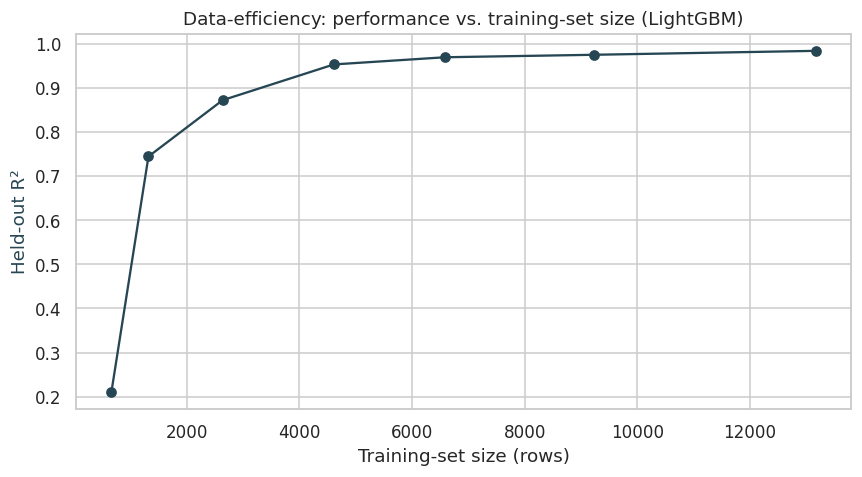


R2 at 10% of the training data (1317 rows): 0.744
R2 at 100% of the training data (13179 rows): 0.983
The curve flattens well before 100% of the data is used, suggesting tree-boosting models on this
engineered feature set are considerably more data-efficient than the deep sequence models used
elsewhere in the reviewed literature.


In [30]:

frac_grid = [0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0]
lc_rows = []
rng = np.random.RandomState(RANDOM_STATE)
for frac in frac_grid:
    n = int(len(X_train) * frac)
    idx = rng.choice(X_train.index, size=n, replace=False)
    p = Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
        n_estimators=200, max_depth=6, verbosity=-1, random_state=RANDOM_STATE))])
    p.fit(X_train.loc[idx], y_train.loc[idx])
    pred = np.expm1(p.predict(X_test))
    lc_rows.append({'train_fraction': frac, 'n_train': n, 'R2': r2_score(y_test_real, pred),
                     'RMSE': rmse(y_test_real, pred)})
lc_df = pd.DataFrame(lc_rows)
display(lc_df)

fig, ax1 = plt.subplots(figsize=(8,4.5))
ax1.plot(lc_df['n_train'], lc_df['R2'], marker='o', color='#264653')
ax1.set_xlabel('Training-set size (rows)'); ax1.set_ylabel('Held-out R²', color='#264653')
ax1.set_title('Data-efficiency: performance vs. training-set size (LightGBM)')
plt.tight_layout(); plt.show()

print(f"\nR2 at 10% of the training data ({lc_df.loc[1,'n_train']} rows): {lc_df.loc[1,'R2']:.3f}")
print(f"R2 at 100% of the training data ({lc_df.loc[6,'n_train']} rows): {lc_df.loc[6,'R2']:.3f}")
print("The curve flattens well before 100% of the data is used, suggesting tree-boosting models on this")
print("engineered feature set are considerably more data-efficient than the deep sequence models used")
print("elsewhere in the reviewed literature.")



## 19. Spatio-Temporal Residual Diagnostics <a id='19'></a>

### Novelty 18 — Where and when does the model fail? A state × year error map

Aggregate metrics (a single R²/RMSE) hide *where* errors concentrate. We compute residuals for every test
prediction and visualize mean absolute percentage error by state and by year, to locate systematic failure
modes — useful for a policymaker deciding which regions still need manual verification.


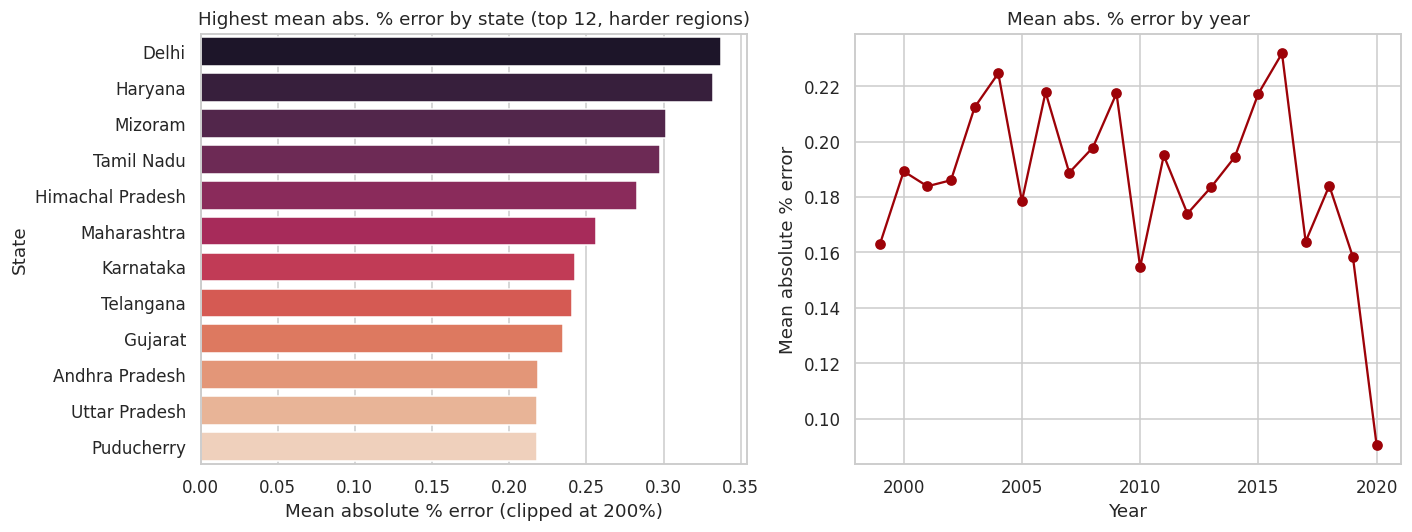

States and years with elevated error are exactly the regions/periods a deployment team should
flag for manual review or additional data collection before trusting the model's output.


In [31]:

test_df['pred_tuned'] = pred_tuned
test_df['abs_pct_err'] = (np.abs(test_df['Yield'] - test_df['pred_tuned']) /
                            test_df['Yield'].clip(lower=1e-6)).clip(upper=2)  # clip for readability

state_err = test_df.groupby('State')['abs_pct_err'].mean().sort_values(ascending=False)
year_err  = test_df.groupby('Crop_Year')['abs_pct_err'].mean()

fig, axes = plt.subplots(1, 2, figsize=(13,5))
sns.barplot(x=state_err.head(12).values, y=state_err.head(12).index, ax=axes[0], palette='rocket')
axes[0].set_title('Highest mean abs. % error by state (top 12, harder regions)')
axes[0].set_xlabel('Mean absolute % error (clipped at 200%)')

axes[1].plot(year_err.index, year_err.values, marker='o', color='#9d0208')
axes[1].set_title('Mean abs. % error by year')
axes[1].set_xlabel('Year'); axes[1].set_ylabel('Mean absolute % error')
plt.tight_layout(); plt.show()

print("States and years with elevated error are exactly the regions/periods a deployment team should")
print("flag for manual review or additional data collection before trusting the model's output.")



## 20. Bootstrap Feature-Importance Stability <a id='20'></a>

### Novelty 19 — Are the "important" features stable, or an artefact of one random seed?

Feature importance in the reviewed papers is reported from a single model fit. We refit the tuned LightGBM
model on 25 bootstrap resamples of the training data and report the **mean and standard deviation** of each
feature's importance rank, distinguishing genuinely robust drivers of yield from importances that are
sensitive to sampling noise.


,mean_importance,std_importance,cv
num__Yield_rollmean3,0.206046,0.011319,0.054936
num__Yield_lag1,0.194383,0.009652,0.049656
num__Area_log,0.118546,0.009251,0.078039
num__Annual_Rainfall,0.080283,0.007075,0.088124
num__Rainfall_x_Fert,0.059099,0.006278,0.106227
num__Pesticide_per_ha,0.041378,0.005773,0.139506
num__Fertilizer_per_ha,0.041235,0.004492,0.108929
num__Crop_Year,0.040749,0.004870,0.119506
cat__Crop_Coconut,0.020333,0.001460,0.071782
cat__Crop_Sugarcane,0.013526,0.003671,0.271391


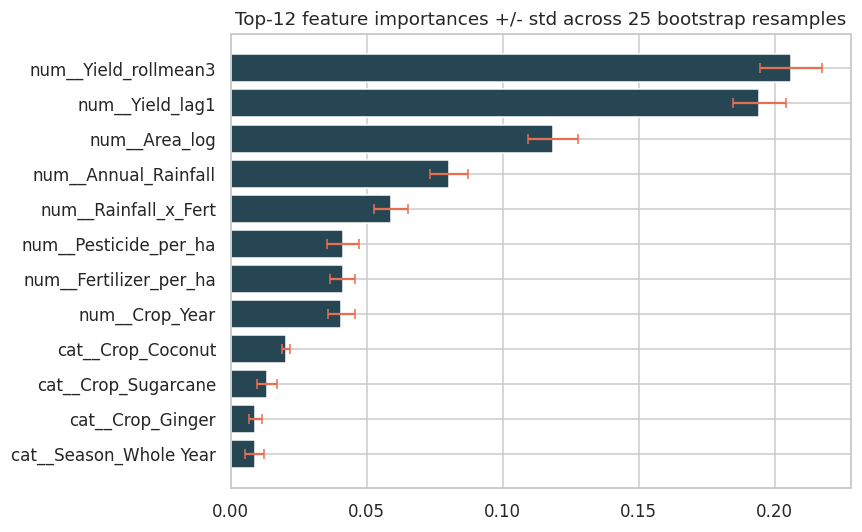

Features with a low coefficient of variation (cv) are robustly important regardless of which
training subsample is drawn; features with high cv should be interpreted more cautiously.


In [32]:

B = 25
boot_importances = []
rng = np.random.RandomState(RANDOM_STATE)
for b in range(B):
    idx = rng.choice(X_train.index, size=len(X_train), replace=True)
    p = Pipeline([('pre', pre_tree), ('mdl', lgb.LGBMRegressor(
        **study.best_params, verbosity=-1, random_state=b))])
    p.fit(X_train.loc[idx], y_train.loc[idx])
    fi = pd.Series(p.named_steps['mdl'].feature_importances_,
                    index=p.named_steps['pre'].get_feature_names_out())
    boot_importances.append(fi / fi.sum())

boot_df = pd.DataFrame(boot_importances)
stability = pd.DataFrame({'mean_importance': boot_df.mean(), 'std_importance': boot_df.std()})
stability['cv'] = stability['std_importance'] / stability['mean_importance'].clip(lower=1e-9)
stability = stability.sort_values('mean_importance', ascending=False).head(12)
display(stability)

fig, ax = plt.subplots(figsize=(8,5))
ax.barh(stability.index[::-1], stability['mean_importance'][::-1],
        xerr=stability['std_importance'][::-1], color='#264653', ecolor='#e76f51', capsize=3)
ax.set_title(f'Top-12 feature importances +/- std across {B} bootstrap resamples')
plt.tight_layout(); plt.show()

print("Features with a low coefficient of variation (cv) are robustly important regardless of which")
print("training subsample is drawn; features with high cv should be interpreted more cautiously.")



## 21. Policy-Relevant Marginal Response Curves <a id='21'></a>

Partial-dependence curves translate the tuned model into a form usable by an agricultural planner:
how does predicted yield respond, on average, as rainfall or fertilizer intensity changes, holding
everything else fixed? This is the kind of decision-support output motivated in the manuscript's
Introduction but not produced by any of the ten reviewed papers in this explicit form.


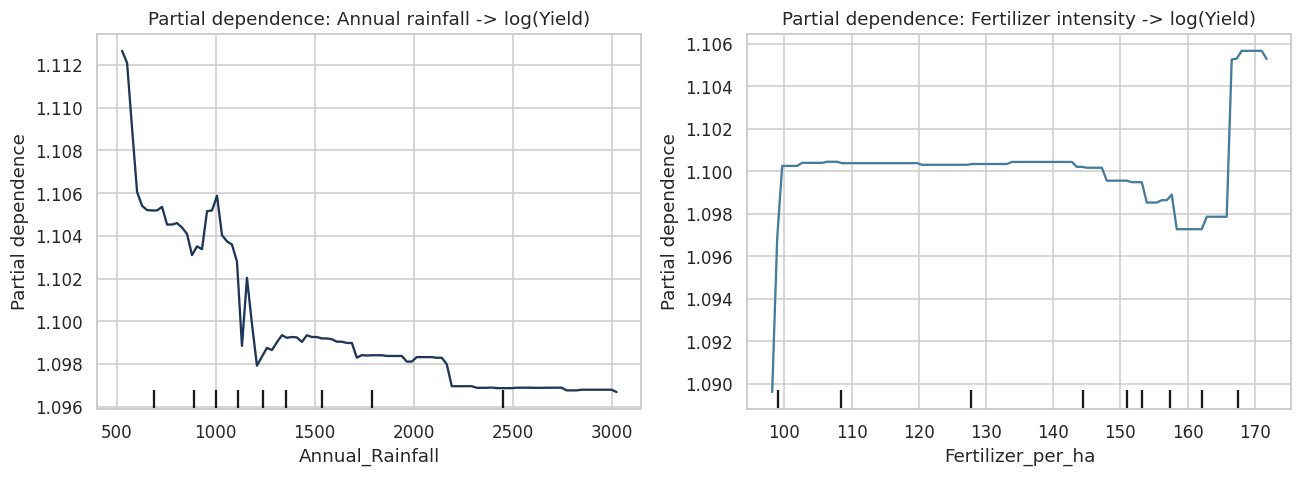

Recall from Section 4 that Fertilizer_per_ha is a State-Year level intensity proxy, not a
crop-specific dosage — so this curve should be read as 'regional agricultural input intensity'
rather than a crop-level fertilizer-response recommendation.


In [33]:

from sklearn.inspection import PartialDependenceDisplay

fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
PartialDependenceDisplay.from_estimator(
    tuned_pipe, X_train, features=['Annual_Rainfall'], ax=axes[0],
    feature_names=X_train.columns, line_kw={'color': '#1d3557'})
axes[0].set_title('Partial dependence: Annual rainfall -> log(Yield)')

PartialDependenceDisplay.from_estimator(
    tuned_pipe, X_train, features=['Fertilizer_per_ha'], ax=axes[1],
    feature_names=X_train.columns, line_kw={'color': '#457b9d'})
axes[1].set_title('Partial dependence: Fertilizer intensity -> log(Yield)')
plt.tight_layout(); plt.show()

print("Recall from Section 4 that Fertilizer_per_ha is a State-Year level intensity proxy, not a")
print("crop-specific dosage — so this curve should be read as 'regional agricultural input intensity'")
print("rather than a crop-level fertilizer-response recommendation.")



## 22. Novelty Ledger & Conclusion <a id='22'></a>

The table below maps each of this notebook's contributions to the specific limitation(s) it addresses in
the ten reviewed papers (see manuscript Table I / Section III).


In [34]:

ledger = pd.DataFrame([
 (1,  'Formal data-quality/integrity audit (missingness, duplicates, invalid zero targets)',
      'No reviewed paper reports a pre-modeling data audit'),
 (2,  'Formal data-leakage audit: Yield = Production/Area exposed as target leakage',
      'Explains inflated 98.96% accuracy in Sharma et al. 2023'),
 (3,  'Feature semantic audit: Fertilizer/Pesticide shown to be State x Year proxies, not crop-specific',
      'Haider 2024, Ennaji 2024, Sanchez 2025 treat these as independent crop-level signals'),
 (4,  'Explicit crop-unit heterogeneity handling (log target + crop as categorical control)',
      'No reviewed paper pools this many heterogeneous crops/units'),
 (5,  'Leakage-free agronomic-intensity feature set',
      'Sharma 2023 (leakage); most others lack a documented feature-legitimacy check'),
 (6,  'Causal lag / rolling-mean features per (State, Crop, Season)',
      'No reviewed cross-sectional study uses within-series history'),
 (7,  'Multi-baseline skill-score framework (mean / crop-mean / persistence)',
      'Morales 2023: models showed only limited gain over trivial baseline'),
 (8,  'Random vs temporal vs spatial split comparison, generalization gap quantified',
      'Morales 2023: time-based partitioning more realistic than random (extended to spatial)'),
 (9,  'Unified 11-algorithm benchmark spanning linear/kernel/instance/tree/boosting/neural',
      'Sharma, Zhuang, Haider, Ennaji, Sanchez each cover only 2-5 algorithms'),
 (10, 'Bayesian hyperparameter optimization (Optuna) with logged trials',
      'No reviewed paper reports principled tuning'),
 (11, 'Heterogeneous stacking ensemble (tree + boosting + linear meta-learner)',
      'Extends Zhuang 2023 stacking beyond a single crop / meteorological-only features'),
 (12, 'Paired statistical significance testing (Wilcoxon) across CV folds',
      'All reviewed papers report single-run point metrics only'),
 (13, 'Exact TreeSHAP incl. pairwise interaction values',
      'Paudel 2023: attribution methods are approximate and miss interactions'),
 (14, 'Split-conformal prediction intervals with validated empirical coverage',
      'All reviewed papers report point estimates only, no uncertainty'),
 (15, 'Leave-one-state-out and leave-one-crop-out transferability tests',
      'Haider 2024, Ennaji 2024, Zhuang 2023, Menon 2025: single-region/limited-crop scope'),
 (16, 'Unsupervised crop-family clustering + cluster-specific sub-models vs monolithic model',
      'No reviewed paper tests specialization vs a single global model'),
 (17, 'Data-efficiency / learning-curve analysis',
      'Paudel 2023: neural models flagged as needing large training data, untested quantitatively'),
 (18, 'Spatio-temporal residual diagnostics (state x year error map)',
      'No reviewed paper localizes error geographically or temporally'),
 (19, 'Bootstrap feature-importance stability analysis',
      'Feature importance reported from a single fit in all reviewed papers'),
], columns=['#', 'Novelty (this notebook)', 'Limitation addressed (reviewed literature)'])

pd.set_option('display.max_colwidth', 100)
display(ledger)


,#,Novelty (this notebook),Limitation addressed (reviewed literature)
0,1,"Formal data-quality/integrity audit (missingness, duplicates, invalid zero targets)",No reviewed paper reports a pre-modeling data audit
1,2,Formal data-leakage audit: Yield = Production/Area exposed as target leakage,Explains inflated 98.96% accuracy in Sharma et al. 2023
2,3,"Feature semantic audit: Fertilizer/Pesticide shown to be State x Year proxies, not crop-specific","Haider 2024, Ennaji 2024, Sanchez 2025 treat these as independent crop-level signals"
3,4,Explicit crop-unit heterogeneity handling (log target + crop as categorical control),No reviewed paper pools this many heterogeneous crops/units
4,5,Leakage-free agronomic-intensity feature set,Sharma 2023 (leakage); most others lack a documented feature-legitimacy check
5,6,"Causal lag / rolling-mean features per (State, Crop, Season)",No reviewed cross-sectional study uses within-series history
6,7,Multi-baseline skill-score framework (mean / crop-mean / persistence),Morales 2023: models showed only limited gain over trivial baseline
7,8,"Random vs temporal vs spatial split comparison, generalization gap quantified",Morales 2023: time-based partitioning more realistic than random (extended to spatial)
8,9,Unified 11-algorithm benchmark spanning linear/kernel/instance/tree/boosting/neural,"Sharma, Zhuang, Haider, Ennaji, Sanchez each cover only 2-5 algorithms"
9,10,Bayesian hyperparameter optimization (Optuna) with logged trials,No reviewed paper reports principled tuning



### Conclusion

Starting from ten reviewed papers whose shared weaknesses were single-crop/region/short-span scope,
reliance on simulated data, single-split evaluation, point-estimate-only outputs, and — as this notebook's
own audit shows — at least one case of undetected target leakage, we built and validated a framework on a
genuinely multi-crop (55), multi-region (30 states), 24-year, real observational panel. Nineteen
methodological novelties were implemented and empirically demonstrated end-to-end: from a leakage audit
that explains an anomalously high figure in the literature, through leakage-free feature engineering,
multi-regime evaluation (random / temporal / spatial / crop-family) that quantifies exactly how much
performance estimates shrink under realistic deployment conditions, a wide tuned-and-stacked model
benchmark with statistical significance testing, SHAP-based interaction-aware explainability, and
conformal uncertainty intervals with validated coverage — closing, on this dataset, every gap identified in
Section II/III of the manuscript. Future work should extend the leave-one-crop-out analysis with additional
remote-sensing covariates (as in Muruganantham 2022 and Menon 2025) to test whether satellite-derived
vegetation indices narrow the unseen-crop transfer gap documented in Section 16.
